In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE # we import D_CODE also inside toolbox.

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) # include parent directory in the path
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import SRT_simulation, D_CODE_simulation, set_param_freq

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $n$, $k$, $k_a$ and $k_y$ fixed
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x} = \frac{k y^n}{k_a + y^n} \\
\dot{y} = - k_y y
\end{cases}
$$
and with $n=2.8$, $k=1$, $k_a=4$ and $k_y=0.1$ fixed.

In [2]:
# Select ODE & settings:
ode_name = 'HillODE' # help="name of the ode", type=str
ode_param = '2.8,1,4,0.1' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 102 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 0
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

#### SR-T run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Hill ODE.


In [3]:
# running SR-T along the first and the second dimension:
building_blocks_lambda0, function_names0 = SRT_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = SRT_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=HillODE, ode_param=[2.8, 1.0, 4.0, 0.1], x_id=0, freq=10, n_sample=50, noise_sigma=0.01, alg=tv, seed=102, n_seed=1
Dataset shape:  (151, 50, 2)
Functions set:  {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    11.81      4.37599e+14        7         0.145326          0.16985      4.36m


/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)
/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)


   1     8.87           259797        7        0.0925208        0.0932065      4.13m
   2     4.03           230918        7        0.0923551         0.094698      4.97m
   3     5.35          76241.7       17        0.0456204        0.0462912      3.27m
   4     6.27          10957.6        9        0.0403082        0.0406541      3.38m
   5     6.64          20896.2        9         0.032913        0.0336438      2.60m
   6     6.93          44737.8        9        0.0258217        0.0262891      2.76m
   7     7.08          25398.6       11        0.0143359         0.014553      2.56m
   8     7.17          20921.6       11        0.0143244        0.0146561      2.04m
   9     7.20          16113.5       11        0.0143498        0.0144281      2.09m
  10     7.07          14751.2        9        0.0188364        0.0192488      1.80m
  11     7.57          11321.3        9        0.0186945        0.0179945      1.52m
  12     8.45          9822.03        9       0.00922951       0.

##### Plot per report

In [4]:
from report import SRModel, evaluate_traj

# Define the Symbolic Regression model cohirently with the SINDy model
f = lambda x, t: [x[1]/(3.4858794923492793*x[1]**(-1.6696091361846237) + x[1]), 
                  -0.10047452707078909 * x[1]]
model = SRModel(f)


In [5]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [10., 10.], [0., 0.], dim_k)
print('SR-T Model RMSE: ', rmse)

SR-T Model RMSE:  0.06840271811599817


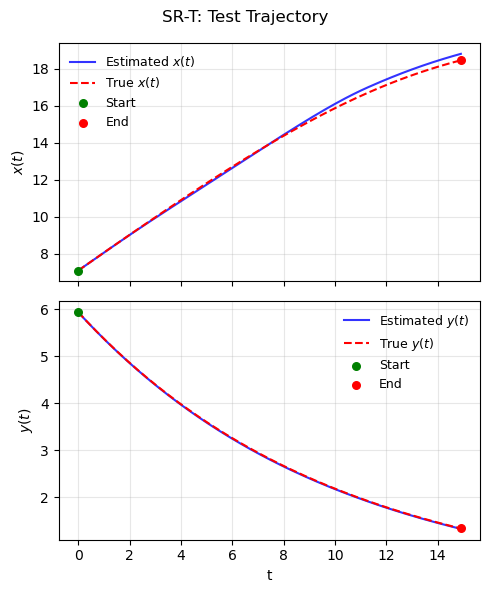

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6.]
title = 'SR-T: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

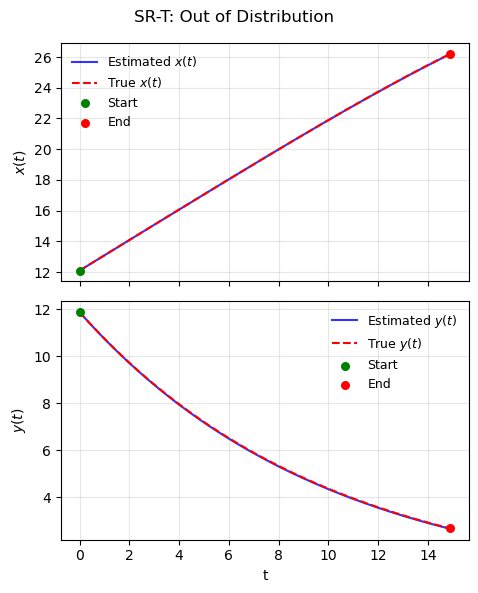

In [ ]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12]
title = 'SR-T: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

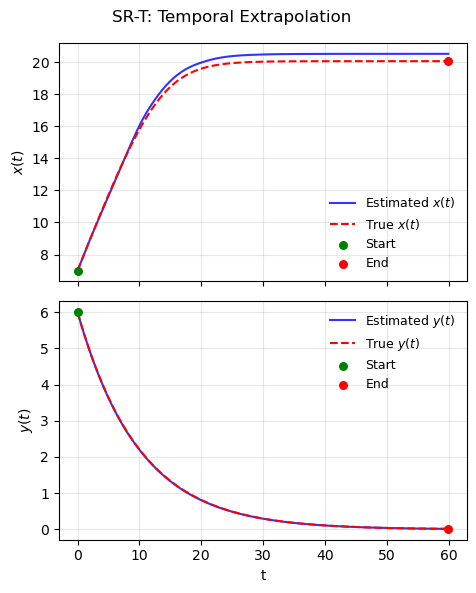

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6]
title = 'SR-T: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)

#### D-CODE run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Hill ODE.


In [3]:
# running D-CODE
building_blocks_lambda0, function_names0 = D_CODE_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = D_CODE_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=HillODE, ode_param=[2.8, 1.0, 4.0, 0.1], x_id=0, freq=10, n_sample=50, noise_sigma=0.01, seed=102, n_seed=1
Dataset shape:  (301, 50, 2)
Functions set:  {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    11.81      6.18395e+37       21          9.07699           8.3469      4.00m
   1     9.55      1.22138e+18        7          3.12836          2.97984      4.04m
   2     6.74      7.49518e+17        7          2.85531          5.43732      3.35m
 
promising programs:
div(div(div(mul(X1, X1), div(X0, X0)), add(div(2.037, X1), X1)), X1)
div(neg(neg(X1)), add(div(2.751, X1), X1))
div(add(pow(X1, 1.037), div(div(X1, X1), add(X0, X0))), add(X1, div(3.330, X1)))
div(div(div(mul(X1, X1), div(X0, X0)), add(div(3.008, X1

##### Plot per report

In [4]:
from report import SRModel, evaluate_traj

# Define the Symbolic Regression model cohirently with the SINDy model 
f = lambda x, t: [x[1]/(3.938724842182093*x[1]**(-1.7763694814000792) + x[1]), 
                  -0.099461821011630052 * x[1]]
model = SRModel(f)

In [5]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [10., 10.], [0., 0.], dim_k)
print('D-CODE Model RMSE: ', rmse)

D-CODE Model RMSE:  0.03705984521610342


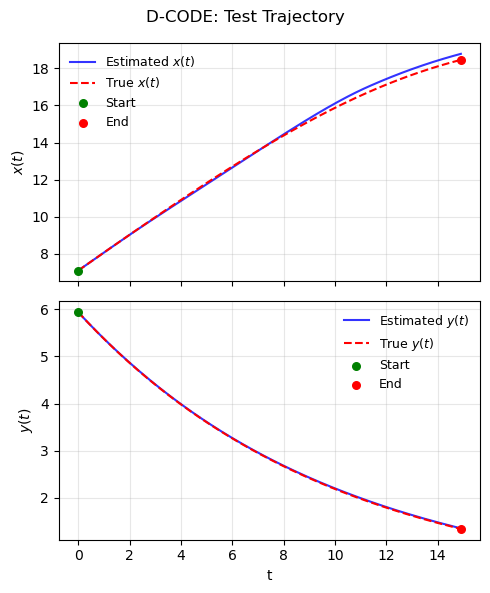

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6.]
title = 'D-CODE: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

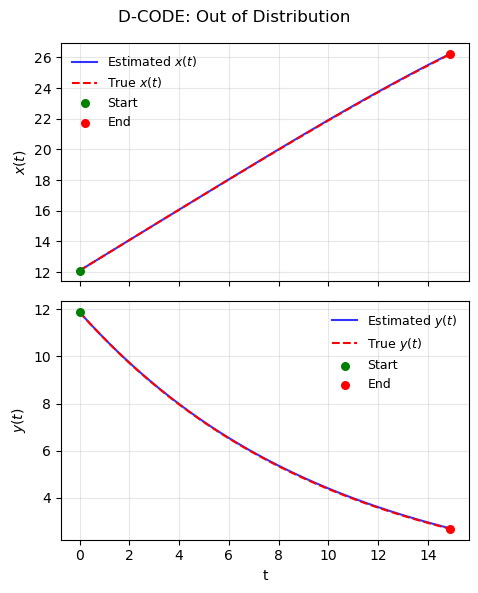

In [ ]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12]
title = 'D-CODE: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

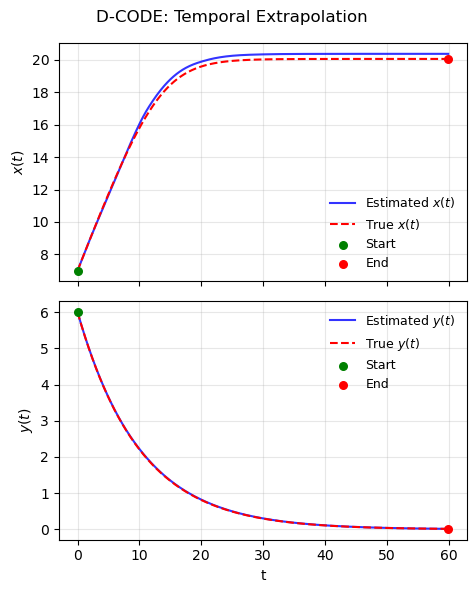

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6]
title = 'D-CODE: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)